# Model 3: CRNN-BiGRU for Environmental Sound Classification
Harshini Rebala (230911001). DataSEC subset: first 5 s of up to 25 clips per class, 16 kHz, log-Mel input, 70/15/15 split (seed 42), CPU training.

## Step 0: Download the subset
Reads only the first 5 s of random clips straight from the Zenodo zip (the full zip is 4 GB). Zenodo rate-limited us, so some clips are skipped.

In [1]:
import io, zipfile, requests
URL = "https://zenodo.org/api/records/15340689/files/PT_DATASET_250314.zip/content"

class HTTPFile(io.RawIOBase):
    """Read-only file object that fetches bytes from a URL with Range requests."""
    def __init__(self, url):
        self.url, self.pos = url, 0
        r = requests.get(url, headers={"Range": "bytes=0-0"}, stream=True)
        self.size = int(r.headers["Content-Range"].split("/")[1]); r.close()
    def seekable(self): return True
    def readable(self): return True
    def tell(self): return self.pos
    def seek(self, off, whence=0):
        self.pos = off if whence == 0 else self.pos + off if whence == 1 else self.size + off
        return self.pos
    def read(self, n=-1):
        end = self.size - 1 if n < 0 else min(self.pos + n - 1, self.size - 1)
        if self.pos > end: return b""
        r = requests.get(self.url, headers={"Range": f"bytes={self.pos}-{end}"})
        self.pos += len(r.content); return r.content

import os
if os.path.exists('subset.npz'):
    print('subset.npz already exists, skipping download')
else:
    # Downloads only the first 5 s of N random clips per class from the remote zip.
    import struct, zlib, random, numpy as np, librosa, requests, time
    from concurrent.futures import ThreadPoolExecutor

    N_PER_CLASS, SR, SECS = 25, 16000, 5
    random.seed(42)
    zf = zipfile.ZipFile(HTTPFile(URL))
    files = [i for i in zf.infolist() if i.filename.endswith(".wav")]
    classes = sorted({i.filename.split("/")[1] for i in files})
    chosen = []
    for c in classes:
        fs = [i for i in files if i.filename.split("/")[1] == c]
        chosen += random.sample(fs, min(N_PER_CLASS, len(fs)))

    def get(a, b):
        for _ in range(5):
            r = requests.get(URL, headers={"Range": f"bytes={a}-{b}"}, timeout=60)
            if r.status_code == 206 and len(r.content) == b - a + 1:
                return r.content
            time.sleep(2)
        raise RuntimeError(f"bad range response {r.status_code} {len(r.content)} for {a}-{b}")

    def load(info):
        try:
            return load_one(info)
        except Exception as e:
            print("skip", info.filename, e); return None

    def load_one(info):
        h = get(info.header_offset, info.header_offset + 29)
        n, m = struct.unpack("<HH", h[26:30])
        pos = info.header_offset + 30 + n + m
        end = info.header_offset + 30 + n + m + info.compress_size - 1
        d, buf = zlib.decompressobj(-15), b""
        while pos <= end:
            stop = min(pos + 131071, end)
            buf += d.decompress(get(pos, stop)); pos = stop + 1
            i = buf.find(b"data")
            if i > 0 and len(buf) - (i + 8) >= 44100 * 2 * SECS: break   # enough for 5 s at 44.1 kHz
        i = buf.find(b"data")
        raw = buf[i + 8:]
        pcm = np.frombuffer(raw[: len(raw) // 2 * 2], dtype="<i2").astype(np.float32) / 32768
        sr = struct.unpack("<I", buf[24:28])[0]
        y = librosa.resample(pcm[: sr * SECS], orig_sr=sr, target_sr=SR)
        y = np.pad(y, (0, max(0, SR * SECS - len(y))))[: SR * SECS]
        return y

    t = time.time()
    with ThreadPoolExecutor(16) as ex:
        X = list(ex.map(load, chosen))
    ok = [k for k, x in enumerate(X) if x is not None]
    X = [X[k] for k in ok]
    y = [classes.index(chosen[k].filename.split("/")[1]) for k in ok]
    np.savez("subset.npz", X=np.array(X, dtype=np.float32), y=np.array(y), classes=np.array(classes))
    print("done", len(X), "clips in", round(time.time() - t), "s")

subset.npz already exists, skipping download


## Step 1: Load audio and make log-Mel spectrograms

In [2]:
# CRNN-BiGRU for environmental sound classification (DataSEC subset)
import time, numpy as np, librosa, torch, torch.nn as nn
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

torch.manual_seed(42); np.random.seed(42)
SR, EPOCHS = 16000, 30


# 1. Load audio and turn each clip into a log-Mel spectrogram
d = np.load("subset.npz")
waves, y, classes = d["X"], d["y"], list(d["classes"])

def logmel(w):
    m = librosa.feature.melspectrogram(y=w, sr=SR, n_fft=1024, hop_length=512, n_mels=64)
    return librosa.power_to_db(m, ref=np.max)

X = np.array([logmel(w) for w in waves])          # (N, 64 mels, 157 frames)
X = (X - X.mean()) / X.std()
X = torch.tensor(X, dtype=torch.float32).unsqueeze(1)   # (N, 1, 64, 157)
y = torch.tensor(y)



## Step 2: Train/validation/test split

In [3]:
# 2. Split 70 / 15 / 15, stratified by class
idx = np.arange(len(y))
tr, rest = train_test_split(idx, test_size=0.30, stratify=y, random_state=42)
va, te = train_test_split(rest, test_size=0.50, stratify=y[rest], random_state=42)



## Step 3: Model: CNN blocks then bidirectional GRU

In [4]:
# 3. Model: CNN blocks -> bidirectional GRU -> linear classifier
class CRNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o),
                                 nn.ReLU(), nn.MaxPool2d((2, 2)))
        self.cnn = nn.Sequential(block(1, 16), block(16, 32), block(32, 64))   # 64 mels -> 8
        self.gru = nn.GRU(64 * 8, 64, num_layers=2, batch_first=True,
                          bidirectional=True, dropout=0.3)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(128, n_classes)
    def forward(self, x):
        x = self.cnn(x)                                # (B, C, mels, time)
        x = x.permute(0, 3, 1, 2).flatten(2)           # (B, time, C*mels)
        x, _ = self.gru(x)
        return self.fc(self.drop(x.mean(dim=1)))       # average over time

model = CRNN(len(classes))
params = sum(p.numel() for p in model.parameters())
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

def run(ids, train):
    model.train(train)
    order = np.random.permutation(ids) if train else ids
    tot, correct, preds = 0.0, 0, []
    for i in range(0, len(order), 32):
        b = order[i:i + 32]
        with torch.set_grad_enabled(train):
            out = model(X[b]); loss = loss_fn(out, y[b])
        if train:
            opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(b)
        p = out.argmax(1); preds += p.tolist(); correct += (p == y[b]).sum().item()
    return tot / len(ids), correct / len(ids), preds



## Step 4: Training

In [5]:
# 4. Train, keep the best model on validation accuracy
hist = {"tl": [], "vl": [], "ta": [], "va": []}
best, t0 = 0, time.time()
for ep in range(EPOCHS):
    tl, ta, _ = run(tr, True); vl, vacc, _ = run(va, False)
    for k, v in zip(hist, (tl, vl, ta, vacc)): hist[k].append(v)
    if vacc > best:
        best = vacc; torch.save(model.state_dict(), "best_crnn.pt")
    print(f"epoch {ep+1:2d}  train loss {tl:.3f} acc {ta:.3f}  val loss {vl:.3f} acc {vacc:.3f}")
train_time = time.time() - t0



epoch  1  train loss 3.017 acc 0.070  val loss 2.984 acc 0.109
epoch  2  train loss 2.642 acc 0.290  val loss 2.782 acc 0.217
epoch  3  train loss 2.394 acc 0.369  val loss 2.632 acc 0.217
epoch  4  train loss 2.187 acc 0.397  val loss 2.462 acc 0.261
epoch  5  train loss 2.028 acc 0.393  val loss 2.167 acc 0.326
epoch  6  train loss 1.856 acc 0.481  val loss 2.027 acc 0.283
epoch  7  train loss 1.742 acc 0.472  val loss 1.774 acc 0.500
epoch  8  train loss 1.597 acc 0.514  val loss 1.739 acc 0.435
epoch  9  train loss 1.510 acc 0.565  val loss 1.651 acc 0.522
epoch 10  train loss 1.398 acc 0.607  val loss 1.611 acc 0.478
epoch 11  train loss 1.280 acc 0.696  val loss 1.592 acc 0.587
epoch 12  train loss 1.187 acc 0.692  val loss 1.477 acc 0.565
epoch 13  train loss 1.079 acc 0.734  val loss 1.459 acc 0.587
epoch 14  train loss 1.009 acc 0.743  val loss 1.454 acc 0.587
epoch 15  train loss 0.912 acc 0.841  val loss 1.330 acc 0.630
epoch 16  train loss 0.782 acc 0.846  val loss 1.318 ac

## Step 5: Test evaluation

In [6]:
# 5. Test the best model
model.load_state_dict(torch.load("best_crnn.pt"))
_, _, pred = run(te, False)
true = y[te].numpy()
res = {"Accuracy": accuracy_score(true, pred),
       "Macro-precision": precision_score(true, pred, average="macro", zero_division=0),
       "Macro-recall": recall_score(true, pred, average="macro", zero_division=0),
       "Macro-F1": f1_score(true, pred, average="macro", zero_division=0)}
lines = [f"{k}: {v:.4f}" for k, v in res.items()]
lines += [f"Parameters: {params:,}", f"Training time: {train_time/60:.1f} min (CPU)",
          f"Train/val/test clips: {len(tr)}/{len(va)}/{len(te)}"]
open("results.txt", "w").write("\n".join(lines))
print("\n".join(lines))



Accuracy: 0.7021
Macro-precision: 0.6515
Macro-recall: 0.7008
Macro-F1: 0.6435
Parameters: 322,806
Training time: 0.4 min (CPU)
Train/val/test clips: 214/46/47


## Step 6: Plots

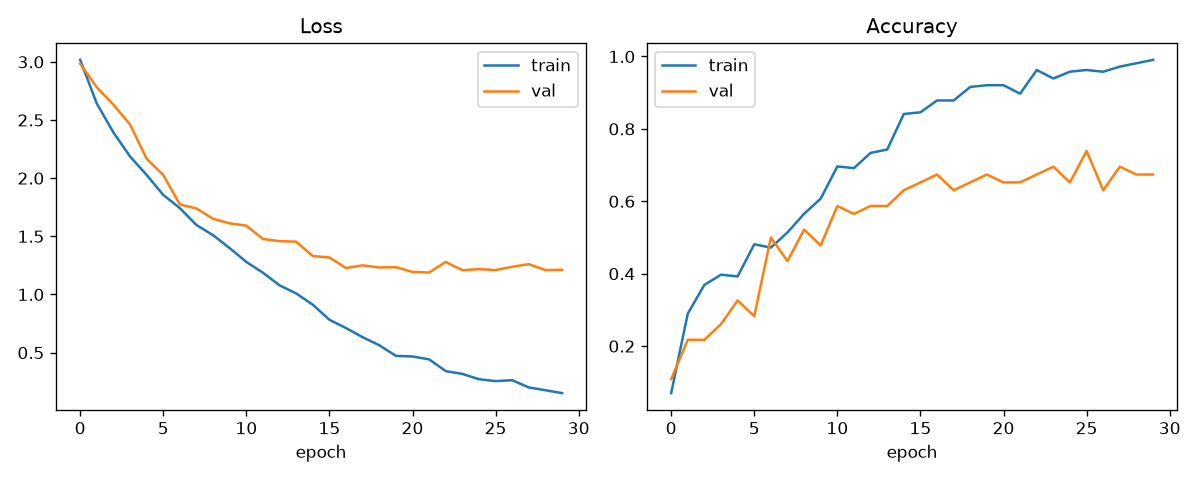

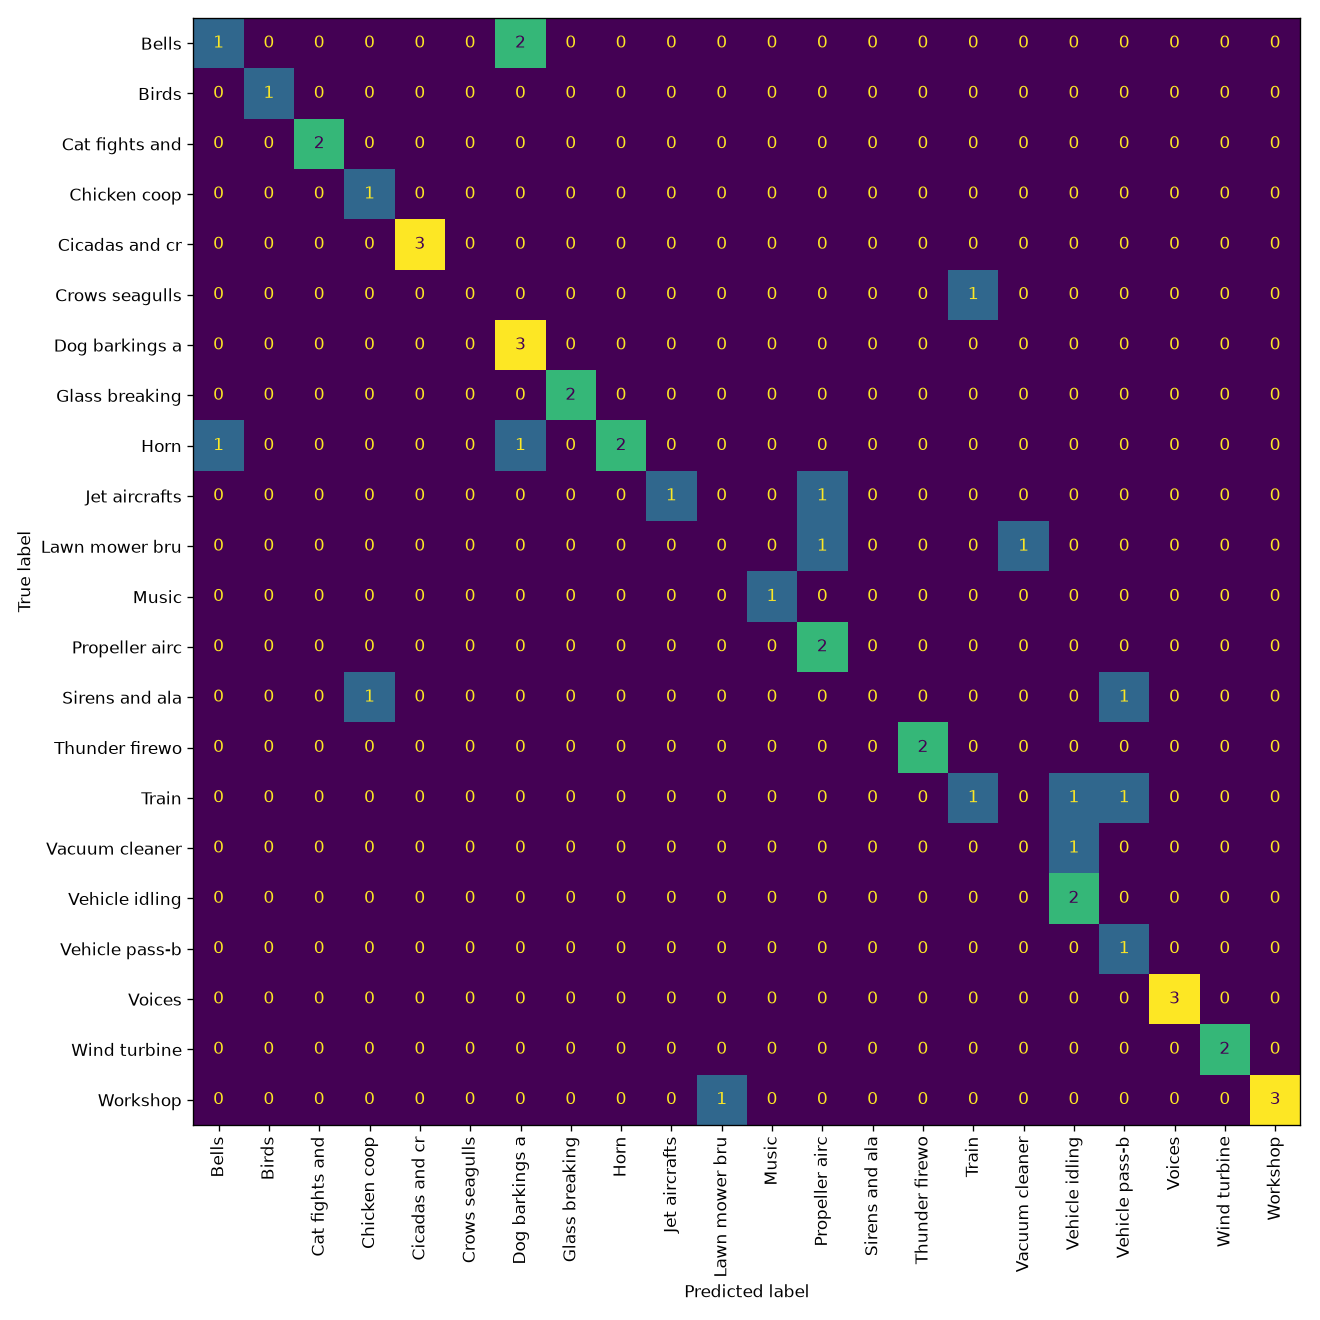

In [7]:
# 6. Plots
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(hist["tl"], label="train"); ax[0].plot(hist["vl"], label="val"); ax[0].set_title("Loss")
ax[1].plot(hist["ta"], label="train"); ax[1].plot(hist["va"], label="val"); ax[1].set_title("Accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig("curves.png", dpi=120)

fig, a = plt.subplots(figsize=(11, 11))
ConfusionMatrixDisplay(confusion_matrix(true, pred, labels=range(len(classes))),
                       display_labels=[c[:14] for c in classes]).plot(ax=a, xticks_rotation=90, colorbar=False)
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=120)
